Going through the linear regression part of the ch 4

First, we will use the normal equation to find the parameter column vector of best fit for the data we are given. Since we are using the normal equation we are assuming that the number of features is small enough that the computational complexity will not be an issue when computing the inverse of the matrix mult

In [63]:
from sklearn.preprocessing import add_dummy_feature #this will add the needed term to multiply into the bias of the parameters since the features dont have that right away
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt


In [ ]:
#creating the patient data and the labels for it
X,y = np.array([[0],[1],[2]]), np.array([1,3,4])
X_b = add_dummy_feature(X,1)
normal_eq_param = np.reshape(np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y,(2,1)) #holds the col vector of the best parameters for our features
predictions = X_b @ normal_eq_param
MSE = np.mean((np.ravel(predictions.T) - y)**2)
MSE #we got a MSE of 0.055, so its very close to 0 which means the parameters are very accurate for our features


array([[1.16666667],
       [1.5       ]])

In [ ]:
lin_model = LinearRegression()
lin_model.fit(X_b, y)
preds = lin_model.predict(X_b)
MSE = np.mean((preds-y)**2)
MSE #we got the same MSE so it means the normal eq works


np.float64(0.05555555555555556)

Now creating a fake data set using random numbe generator with a line that we made along with some normally ditributed noise so that the data does not fall directly on the line

In [75]:
rng = np.random.default_rng(seed=42) #going to use to create our random data of size (100,1) and then (100,2) with the intercept dummy coefficient added
m = 100 #number of rows
X = 2 * rng.random((m,1)) #these are our features
X_b = add_dummy_feature(X) #adds the 1 feature to go into the bias term of params vector
y = 4 + 3*X + rng.standard_normal((m,1)) #this adds random noise to our line normally distributed so the data is not directly on the line
normal_eq_values = np.linalg.inv(X_b.T@X_b) @ X_b.T@y 
preds = X_b @ normal_eq_values
MSE = np.mean((preds-y)**2)
MSE #MSE of almost 1 so its not bad at all
normal_eq_values


array([[3.94869973],
       [3.03831479]])

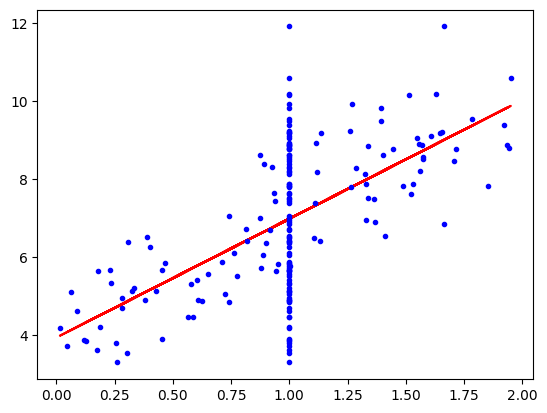

In [74]:
plt.plot(X, preds,'r-', label='predictions')
plt.plot(X_b,y,'b.')
plt.show()